# Text-to-Image Generation with a Pretrained Stable Diffusion Model

**Names:** Amruta Sunil Kanase

**PRN:** 202401110042

**Batch:** A1

In this notebook we use a pretrained Stable Diffusion model (`segmind/tiny-sd`, a distilled version of Stable Diffusion) from the Hugging Face **Diffusers** library to generate images from text prompts.
We then study how the following settings change the output:

1. **Number of inference steps** (`num_inference_steps`): how many times the model removes noise from the image
2. **Guidance scale** (`guidance_scale`): how strongly the image is pushed to follow the text prompt
3. **Prompt design and negative prompts**
4. **Sampling method (scheduler)**: PNDM, DDIM, Euler, Euler Ancestral and DPM-Solver++

## 1. Install libraries

In [1]:
!pip install -q --upgrade diffusers accelerate transformers safetensors huggingface_hub

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.


## 2. Load the pretrained model

In [2]:
import time
import torch
from diffusers import DiffusionPipeline
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
print("Using device:", device)

model_id = "segmind/tiny-sd"

pipe = DiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=dtype
)

pipe = pipe.to(device)
pipe.set_progress_bar_config(disable=True)   # hide the per-image progress bar

Using device: cuda


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/584 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


In [3]:
print(f"Is CUDA available?: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device name: {torch.cuda.get_device_name(0)}")

Is CUDA available?: True
Device name: Tesla T4


### 2.1 Components of the Stable Diffusion pipeline

A Stable Diffusion pipeline is made of four main parts that work together:

| Component | Class | Role |
|---|---|---|
| **Text encoder** | `CLIPTextModel` (+ tokenizer) | Converts the text prompt into numerical embeddings that the U-Net can use as a condition. |
| **U-Net** | `UNet2DConditionModel` | The denoising network. At every step it predicts the noise in the latent image, guided by the text embeddings. |
| **Scheduler** | e.g. `PNDMScheduler` | The sampling method. It decides the noise levels over the steps and how the predicted noise is removed at each step. |
| **VAE** | `AutoencoderKL` | Works in a compressed *latent space*. The decoder turns the final latent into a full-size RGB image (the encoder is used for image-to-image). |

**Pipeline flow:** prompt -> text encoder -> embeddings. Random noise (latent) -> U-Net + scheduler repeated for N steps (with classifier-free guidance) -> clean latent -> VAE decoder -> final image.
Working in latent space (8x smaller in each dimension) makes Stable Diffusion much faster than diffusing in pixel space.

In [4]:
print("Text encoder :", type(pipe.text_encoder).__name__)
print("Tokenizer    :", type(pipe.tokenizer).__name__)
print("U-Net        :", type(pipe.unet).__name__)
print("Scheduler    :", type(pipe.scheduler).__name__)
print("VAE          :", type(pipe.vae).__name__)

def n_params(m): return sum(p.numel() for p in m.parameters()) / 1e6
print(f"\nParameters (millions) -> text encoder: {n_params(pipe.text_encoder):.0f}, "
      f"U-Net: {n_params(pipe.unet):.0f}, VAE: {n_params(pipe.vae):.0f}")

# keep the default scheduler config so we can restore it after the scheduler experiment
default_scheduler_config = pipe.scheduler.config

Text encoder : CLIPTextModel
Tokenizer    : CLIPTokenizer
U-Net        : UNet2DConditionModel
Scheduler    : DPMSolverMultistepScheduler
VAE          : AutoencoderKL

Parameters (millions) -> text encoder: 123, U-Net: 323, VAE: 84


## 3. Generate an image from a text prompt

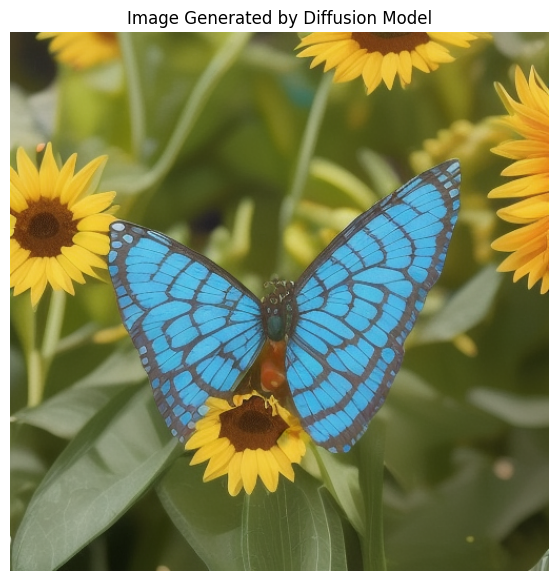

In [5]:
prompt = """
A beautiful blue and orange butterfly resting gently on a bright yellow sunflower,
delicate patterned wings, fresh green leaves and a soft natural garden background,
warm morning sunlight, realistic nature photography, sharp focus on the butterfly
and flower, natural colours, peaceful atmosphere
"""

image = pipe(
    prompt,
    num_inference_steps=25,
    guidance_scale=7.5
).images[0]

plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.axis('off')
plt.title("Image Generated by Diffusion Model")
plt.show()

**Observation:** After running the cell, the generated image closely matches the given prompt. A beautiful blue butterfly with detailed and symmetrical wings is resting on a bright yellow sunflower. The background contains green leaves and several blooming sunflowers, creating a natural garden environment. The image has soft natural lighting, vibrant colors, and a slightly blurred background that highlights the butterfly. Overall, the generated image is realistic, clear, and visually appealing.

## 4. Helper functions

To compare settings fairly we use the **same random seed** every time. Then the only thing that changes between images is the setting we are testing.

In [7]:
def generate(prompt, steps=25, guidance=7.5, seed=42, negative_prompt=None):
    # Use the same starting noise for fair comparisons.
    generator = torch.Generator(device=device).manual_seed(seed)
    start = time.time()
    img = pipe(
        prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=steps,
        guidance_scale=guidance,
        generator=generator
    ).images[0]
    return img, time.time() - start


def show_images(images, titles, figsize=(20, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(img)
        plt.title(title)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

## 5. Experiment 1: Effect of the number of inference steps

The model starts from pure noise and removes a little noise at every step. We keep `guidance_scale = 7.5` fixed and change only the number of steps.

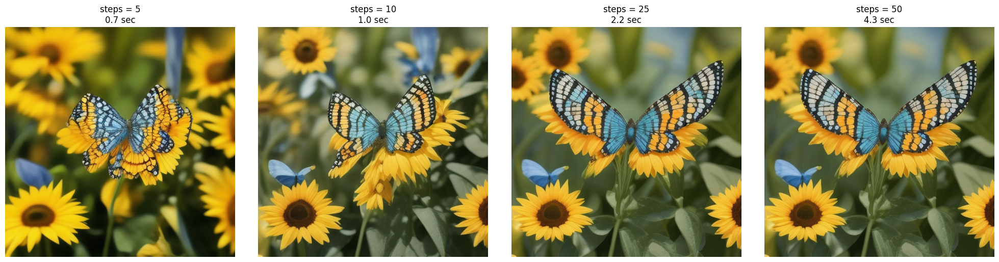

In [8]:
steps_list = [5, 10, 25, 50]
images, titles, times = [], [], []

for s in steps_list:
    img, t = generate(prompt, steps=s, guidance=7.5)
    images.append(img)
    times.append(t)
    titles.append(f"steps = {s}\n{t:.1f} sec")

show_images(images, titles)

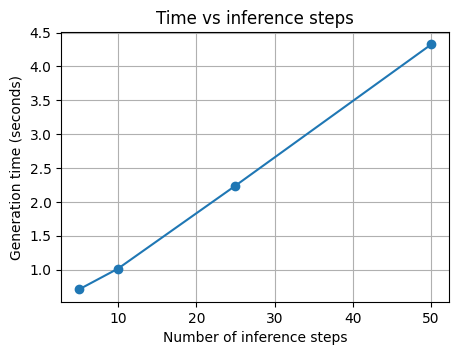

In [9]:
plt.figure(figsize=(5, 3.5))
plt.plot(steps_list, times, marker="o")
plt.xlabel("Number of inference steps")
plt.ylabel("Generation time (seconds)")
plt.title("Time vs inference steps")
plt.grid(True)
plt.show()

**Observations**

After comparing the images generated at different inference steps, we can observe that image quality improves as the number of steps increases.
- 5 steps: The butterfly is recognizable, but its wings and patterns look slightly rough and less detailed.
- 10 steps: The butterfly's wing structure and sunflower details become clearer, with improved colors and appearance.
- 25 steps: The butterfly has more defined wing patterns, better symmetry, and sharper details. The flowers and background also look more realistic.
- 50 steps: The image quality is very similar to 25 steps, with slight improvements in details and clarity.

**Conclusion:** Increasing inference steps generally improves image quality and detail, but it also increases generation time. In this experiment, 25 steps provide a good balance between image quality and generation speed, while 50 steps take longer with only minor visible improvements.

## 6. Experiment 2: Effect of the guidance scale

The guidance scale controls how closely the image follows the text prompt (classifier-free guidance). We keep `steps = 25` fixed and change only the guidance scale.

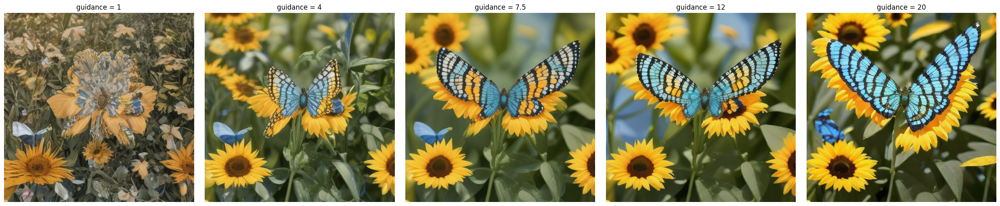

In [10]:
guidance_list = [1, 4, 7.5, 12, 20]
images, titles = [], []

for g in guidance_list:
    img, t = generate(prompt, steps=25, guidance=g)
    images.append(img)
    titles.append(f"guidance = {g}")

show_images(images, titles, figsize=(25, 5))

**Observations**

After comparing the images generated with different guidance scale values, we can observe that guidance affects how closely the generated image follows the given prompt.
- Guidance = 1: Prompt conditioning is very weak. The butterfly and sunflower details are unclear, and the image looks less realistic.
- Guidance = 4: The butterfly becomes more recognizable, with improved wing patterns and clearer sunflower details.
- Guidance = 7.5: The image shows a good balance of prompt accuracy, natural colors, and realistic details.
- Guidance = 12: The butterfly's wings and flower details become more prominent, with stronger colors and contrast.
- Guidance = 20: The butterfly appears larger and more vibrant, but the image looks slightly over-processed with very strong colors.

**Conclusion:** Increasing the guidance scale improves prompt adherence and makes the generated subject more prominent. However, very high guidance values can produce oversaturated colors and unnatural results. In this experiment, a guidance scale of 7.5 provides a good balance between image quality and prompt adherence.

## 7. Experiment 3: Effect of changing the prompt

We keep steps and guidance fixed (25 and 7.5) and only change the text.

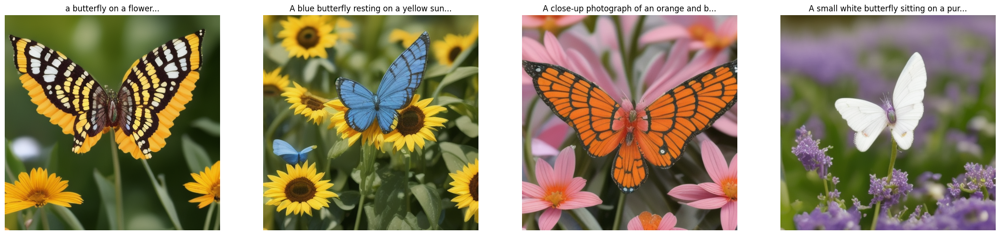

In [11]:
prompts = [
    "a butterfly on a flower",
    "A blue butterfly resting on a yellow sunflower, green leaves, natural garden background",
    "A close-up photograph of an orange and blue butterfly with detailed patterned wings resting on a pink flower, soft morning light",
    "A small white butterfly sitting on a purple lavender flower in a peaceful garden, realistic nature photography",
]

images, titles = [], []
for p in prompts:
    img, t = generate(p, steps=25, guidance=7.5)
    images.append(img)
    titles.append(p[:40] + "...")

show_images(images, titles, figsize=(22, 5))

**Observations**

After comparing the images generated using different text prompts, we can observe that adding more descriptive details changes the appearance and quality of the generated images.
- Prompt 1: The short prompt generates a butterfly with yellow and black wings on a flower. The result is attractive but lacks specific details.
- Prompt 2: Adding the butterfly's blue colour, yellow sunflower and garden setting produces a clearer image that better matches the description.
- Prompt 3: The detailed prompt generates a close-up orange butterfly with clearly visible wing patterns and pink flowers. The image has sharper details and a more focused composition.
- Prompt 4: Changing the butterfly colour to white and the flowers to purple produces a completely different but visually appealing image.

**Conclusion:** Detailed prompts give better control over image generation. Specifying colours, flower types, backgrounds and photography styles helps the model generate images closer to the expected result.

## 8. Experiment 4: Prompt engineering and negative prompts

A good prompt usually has the structure: **subject + details + style + lighting + quality words**.
A **negative prompt** tells the model what to avoid. It is used in classifier-free guidance as the "unconditional" direction, so the model is pushed away from those concepts.
(Note: negative prompts have no effect when `guidance_scale = 1`, because guidance is turned off.)

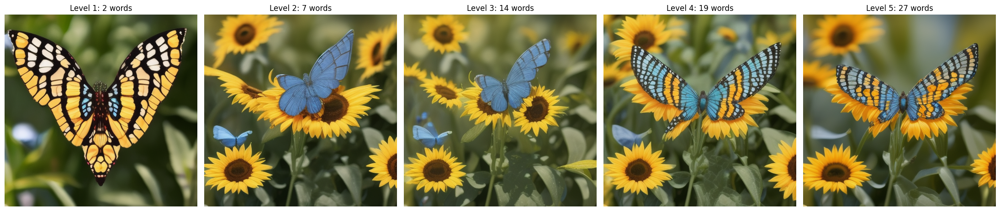

Level 1: a butterfly
Level 2: a blue butterfly sitting on a sunflower
Level 3: a blue butterfly sitting on a bright yellow sunflower, green leaves, soft morning light
Level 4: a blue and orange butterfly resting on a yellow sunflower, delicate patterned wings, fresh green leaves, natural garden background
Level 5: a blue and orange butterfly resting on a yellow sunflower, intricate wing patterns, soft natural morning light, shallow depth of field, professional macro nature photography, sharp focus


In [12]:
# 8.1 Progressively better prompts (same subject, same seed)
prompt_levels = [
    "a butterfly",
    "a blue butterfly sitting on a sunflower",
    "a blue butterfly sitting on a bright yellow sunflower, green leaves, soft morning light",
    "a blue and orange butterfly resting on a yellow sunflower, delicate patterned wings, fresh green leaves, natural garden background",
    "a blue and orange butterfly resting on a yellow sunflower, intricate wing patterns, soft natural morning light, shallow depth of field, professional macro nature photography, sharp focus",
]
images, titles = [], []
for i, p in enumerate(prompt_levels):
    img, _ = generate(p, steps=25, guidance=7.5)
    images.append(img)
    titles.append(f"Level {i+1}: {len(p.split())} words")
show_images(images, titles, figsize=(22, 5))
for i, p in enumerate(prompt_levels):
    print(f"Level {i+1}: {p}")

**Observations (prompt structure)**

After comparing the five images generated using progressively detailed prompts, we can observe that adding more descriptive words improves control over the generated image.
- Level 1 (2 words): The simple prompt generates a butterfly, but its colour, background and surroundings are not specified.
- Level 2 (7 words): Adding the blue butterfly and sunflower makes the subject and flower more recognizable.
- Level 3 (14 words): Specifying yellow sunflowers, green leaves and morning light creates a more detailed garden scene.
- Level 4 (19 words): Adding wing patterns and a natural garden background improves the butterfly's appearance and overall image quality.
- Level 5 (27 words): The detailed prompt produces a more controlled image with patterned wings, natural lighting, shallow depth of field and sharper focus.

**Conclusion:** As the prompt becomes more descriptive, the generated images become more specific and visually controlled. Adding details about the subject, colours, environment, lighting and photography style helps achieve better results.

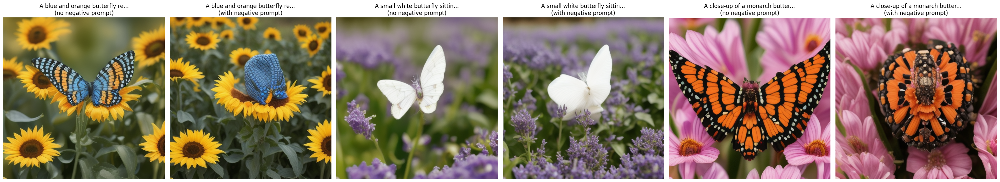

Negative prompt used: blurry, low quality, distorted butterfly wings, extra wings, deformed flower, unrealistic colours, cartoon, painting, watermark, text, noise, overexposure


In [13]:
# 8.2 Effect of a negative prompt (same prompt, same seed, same settings)
neg = "blurry, low quality, distorted butterfly wings, extra wings, deformed flower, unrealistic colours, cartoon, painting, watermark, text, noise, overexposure"

test_prompts = [
    "A blue and orange butterfly resting on a yellow sunflower, realistic nature photography",
    "A small white butterfly sitting on a purple lavender flower in a green garden, soft natural light",
    "A close-up of a monarch butterfly resting on a pink flower, detailed wings and petals, macro photography",
]

images, titles = [], []
for p in test_prompts:
    img_a, _ = generate(p, steps=25, guidance=7.5)
    img_b, _ = generate(p, steps=25, guidance=7.5, negative_prompt=neg)
    images += [img_a, img_b]
    titles += [p[:30] + "...\n(no negative prompt)", p[:30] + "...\n(with negative prompt)"]

show_images(images, titles, figsize=(30, 5.5))
print("Negative prompt used:", neg)

**Observations (negative prompts)**

After comparing the butterfly images generated with and without negative prompts, we can observe some differences in image quality and appearance.
- Without negative prompt: The first image looks natural and colourful, but some details may appear distorted. The second image shows a clear white butterfly, while the third has well-defined orange and black wing patterns.
- With negative prompt: The first image shows some unwanted distortion in the butterfly's wings. The second image has smoother white wings and a clean purple flower background. The third image shows a more unusual wing arrangement and a slightly distorted butterfly shape.
- The negative prompt helps specify unwanted features such as blurriness, extra wings, distorted shapes, and low-quality details, but it does not completely eliminate them.

**Conclusion:** Negative prompts help guide the model by telling it what to avoid. However, their effectiveness can vary depending on the subject and generation settings. In this experiment, the results show that negative prompts do not always guarantee a better image, but they help control certain unwanted visual elements.

## 9. Experiment 5: Effect of the sampling method (scheduler)

The **scheduler** (sampler) decides how the noise is removed at every step. All schedulers use the same U-Net, but they differ in the maths used for each step, so they differ in **speed, quality at low step counts, and randomness**.

| Scheduler | Short description |
|---|---|
| **PNDM** | Pseudo numerical method, the default for Stable Diffusion v1. Good quality, deterministic. |
| **DDIM** | Deterministic version of DDPM. Allows few steps, gives consistent results for the same seed. |
| **Euler** | Simple and fast ODE solver, deterministic. |
| **Euler Ancestral (Euler-A)** | Adds fresh noise at each step, so it never fully "converges"; the image keeps changing with the step count. More creative, less predictable. |
| **DPM-Solver++ (DPM++)** | High-order solver that gives good quality in only 15 to 25 steps. |

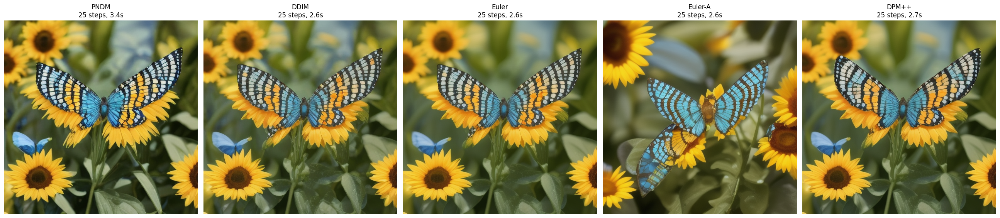

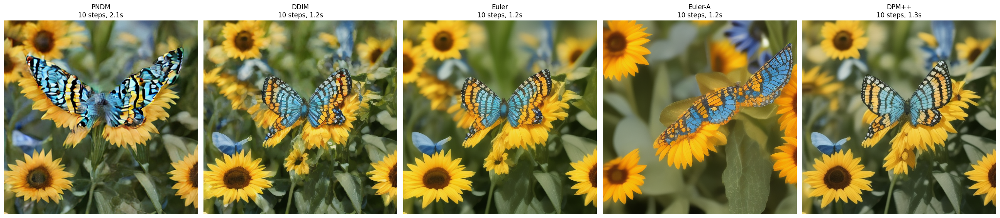

In [14]:
from diffusers import (PNDMScheduler, DDIMScheduler, EulerDiscreteScheduler,
                       EulerAncestralDiscreteScheduler, DPMSolverMultistepScheduler)

schedulers = {
    "PNDM": PNDMScheduler,
    "DDIM": DDIMScheduler,
    "Euler": EulerDiscreteScheduler,
    "Euler-A": EulerAncestralDiscreteScheduler,
    "DPM++": DPMSolverMultistepScheduler,
}

def run_schedulers(steps, prompt=prompt):
    imgs, titles, times = [], [], []
    for name, cls in schedulers.items():
        pipe.scheduler = cls.from_config(default_scheduler_config)
        img, t = generate(prompt, steps=steps, guidance=7.5)
        imgs.append(img); times.append(t)
        titles.append(f"{name}\n{steps} steps, {t:.1f}s")
    return imgs, titles, times

# 9.1 Same number of steps (25)
imgs_25, titles_25, times_25 = run_schedulers(25)
show_images(imgs_25, titles_25, figsize=(26, 5.5))

# 9.2 Few steps (10): which sampler gives a good image fastest?
imgs_10, titles_10, times_10 = run_schedulers(10)
show_images(imgs_10, titles_10, figsize=(26, 5.5))

# restore the default scheduler for the remaining experiments
pipe.scheduler = PNDMScheduler.from_config(default_scheduler_config)

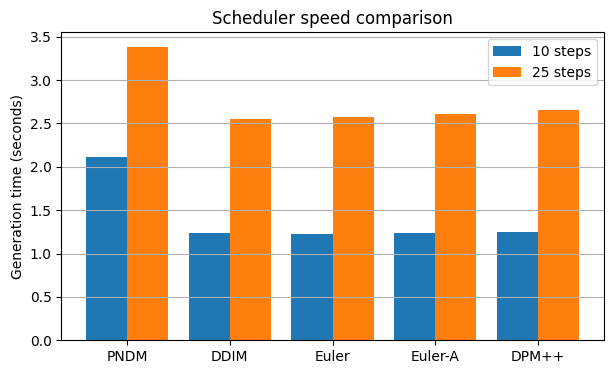

In [15]:
# Speed comparison of schedulers
names = list(schedulers.keys())
x = range(len(names))
plt.figure(figsize=(7, 4))
plt.bar([i - 0.2 for i in x], times_10, width=0.4, label="10 steps")
plt.bar([i + 0.2 for i in x], times_25, width=0.4, label="25 steps")
plt.xticks(list(x), names)
plt.ylabel("Generation time (seconds)")
plt.title("Scheduler speed comparison")
plt.legend(); plt.grid(axis="y")
plt.show()

**Observations (schedulers)**

Observation:

After comparing the images generated using different schedulers (PNDM, DDIM, Euler, Euler-A and DPM++), we can observe differences in image quality, butterfly details and generation time.
- PNDM: Produces a colourful butterfly with visible wing patterns and sunflower details. However, at 10 steps, some wing details appear distorted.
- DDIM: Generates a clear butterfly with well-defined wings and flowers. It provides consistent-looking results at both step settings.
- Euler: Produces detailed butterfly wings with good colour contrast and a natural garden background.
- Euler-A: Generates more variation in the butterfly's position and appearance. The results look different from the other schedulers.
- DPM++: Produces balanced images with clear wing patterns, sharp details and attractive colours.
Generation Time Comparison:
- At 25 steps, generation times range from 2.6 to 3.4 seconds.
- At 10 steps, generation times range from 1.2 to 2.1 seconds.
- DDIM and Euler are among the faster schedulers in this experiment.

**Conclusion:** Different schedulers produce different visual results even when using the same prompt. DDIM and Euler provide a good balance of image quality and generation speed in this experiment, while Euler-A introduces more variation. The best scheduler depends on the required image quality, consistency and generation time.

## 10. Combined effect: steps and guidance together

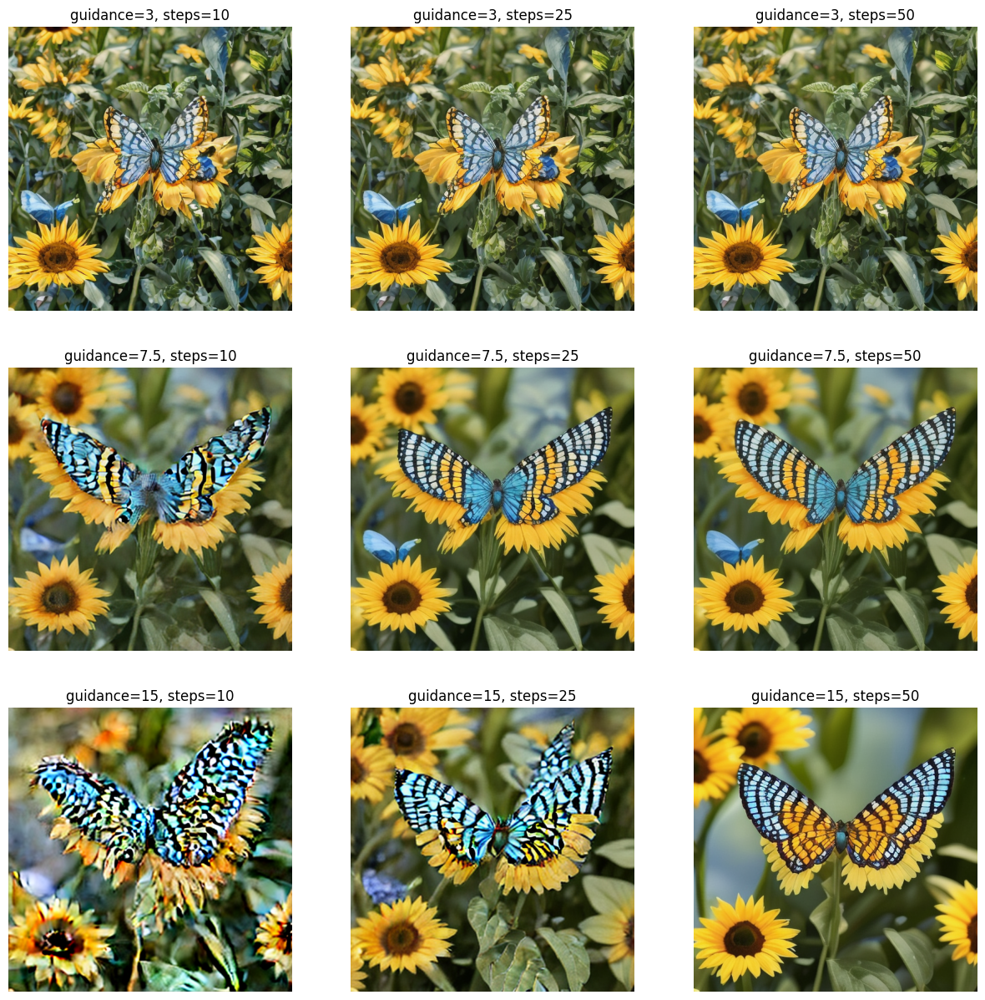

In [16]:
steps_values = [10, 25, 50]
guidance_values = [3, 7.5, 15]

plt.figure(figsize=(15, 15))
k = 1
for g in guidance_values:
    for s in steps_values:
        img, _ = generate(prompt, steps=s, guidance=g)
        plt.subplot(3, 3, k)
        plt.imshow(img)
        plt.title(f"guidance={g}, steps={s}")
        plt.axis('off')
        k += 1
plt.show()

**Observations**

After comparing the images generated using different combinations of guidance scale and inference steps, we can observe that both parameters affect image quality and prompt adherence.
- Guidance = 3: The butterfly and sunflower are recognizable, but the images have less-defined wing patterns and weaker details. Increasing the steps from 10 to 50 produces some improvement.
- Guidance = 7.5: At 10 steps, the butterfly's wings appear distorted. At 25 steps, the wing patterns become clearer, and at 50 steps, the image looks more refined with better details.
- Guidance = 15: At 10 steps, the butterfly has noticeable distortions and unnatural patterns. At 25 steps, some improvements are visible, while 50 steps produces a clearer and more balanced butterfly image.

**Conclusion:** Inference steps control the amount of refinement during image generation, while guidance scale controls how strongly the model follows the prompt. A combination of guidance scale 7.5 and 25–50 steps produces good results in this experiment. Very high guidance with fewer steps can lead to distorted images.

## 11. Quantitative check: CLIP score

So far the comparison was visual. We can also measure **prompt-image similarity** with a CLIP model (higher score = the image matches the text better). This is only a rough indicator, but it supports the visual observations.

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (2 outputs left out)

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

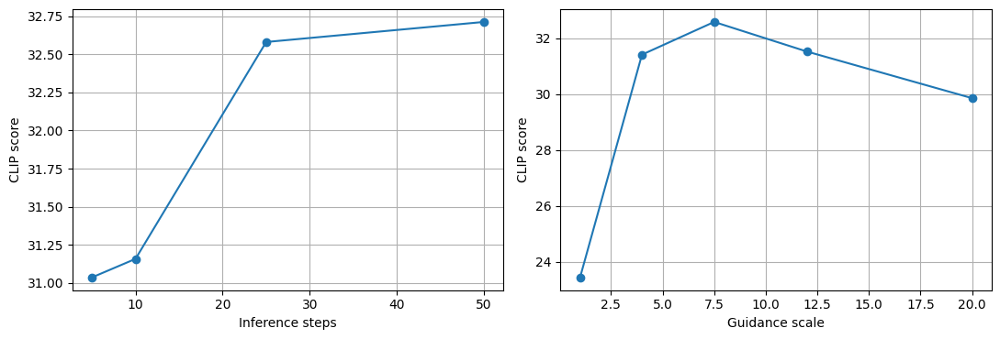

Steps   : {5: 31.0, 10: 31.2, 25: 32.6, 50: 32.7}
Guidance: {1: 23.4, 4: 31.4, 7.5: 32.6, 12: 31.5, 20: 29.9}


In [17]:
from transformers import CLIPProcessor, CLIPModel

clip_id = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(clip_id).to(device).eval()
clip_proc = CLIPProcessor.from_pretrained(clip_id)

@torch.no_grad()
def clip_score(img, text):
    inputs = clip_proc(text=[text], images=img, return_tensors="pt", padding=True).to(device)
    out = clip_model(**inputs)
    return out.logits_per_image.item()

# CLIP score vs guidance scale
g_values = [1, 4, 7.5, 12, 20]
g_scores = [clip_score(generate(prompt, steps=25, guidance=g)[0], prompt.strip()) for g in g_values]

# CLIP score vs inference steps
s_values = [5, 10, 25, 50]
s_scores = [clip_score(generate(prompt, steps=s, guidance=7.5)[0], prompt.strip()) for s in s_values]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(s_values, s_scores, marker="o"); ax[0].set_xlabel("Inference steps"); ax[0].set_ylabel("CLIP score"); ax[0].grid(True)
ax[1].plot(g_values, g_scores, marker="o"); ax[1].set_xlabel("Guidance scale"); ax[1].set_ylabel("CLIP score"); ax[1].grid(True)
plt.tight_layout(); plt.show()

print("Steps   :", dict(zip(s_values, [round(v, 1) for v in s_scores])))
print("Guidance:", dict(zip(g_values, [round(v, 1) for v in g_scores])))

**Observations (CLIP score)**

After analysing the CLIP scores and graphs, we can observe how inference steps and guidance scale affect image-text alignment.
- Inference Steps: At 5 steps, the CLIP score is 31.0. It increases slightly to 31.2 at 10 steps, then rises to 32.6 at 25 steps. At 50 steps, it reaches 32.7, showing only a small improvement.
- Guidance = 1: The CLIP score is 23.4, indicating weak alignment between the generated image and the prompt.
- Guidance = 4: The score increases to 31.4, showing better prompt alignment.
- Guidance = 7.5: The highest score of 32.6 is achieved, indicating the strongest image-text alignment in this experiment.
- Guidance = 12: The score decreases to 31.5.
- Guidance = 20: The score further decreases to 29.9, indicating that excessive guidance does not necessarily improve prompt alignment.

**Conclusion:** The results show that increasing inference steps generally improves CLIP scores, but the improvement becomes smaller at higher step counts. A guidance scale of 7.5 gives the highest CLIP score in this experiment. Overall, 25 inference steps and a guidance scale of 7.5 provide a good balance between image-text alignment and generation time.

## 12. Conclusion

| Setting | Too low | Good range | Too high |
|---|---|---|---|
| Inference steps | Rough, distorted shapes, missing details | about 20 to 30 | Very little extra quality, much slower |
| Guidance scale | Ignores the prompt, messy image | about 7 to 12 | Over-saturated, harsh contrast, unwanted objects |
| Prompt detail | Generic image, random choices by the model | Subject + style + lighting + quality words | Too many words may be ignored by a small model |
| Negative prompt | - | Short list of unwanted qualities | Not useful if guidance is 1 |
| Scheduler | PNDM needs more steps | DPM++ / Euler / DDIM at 15 to 25 steps | Euler-A changes with steps (stochastic) |

- The Stable Diffusion pipeline has four main parts: the **text encoder** (prompt to embeddings), the **U-Net** (noise prediction), the **scheduler** (sampling method) and the **VAE** (latent to image).
- **Inference steps** control how much the noise is cleaned. More steps help only up to a point, then they just cost time (time grows linearly with steps).
- **Guidance scale** controls how strictly the image follows the prompt. The best images come from a medium value.
- **Prompt design** and **negative prompts** give extra control over content and style.
- **Schedulers** change the quality reached for a given number of steps. Better solvers (DPM++, Euler, DDIM) allow fewer steps, which saves time.
- Best settings for this model: around **25 steps** (about 20 with DPM++), guidance of about **7.5**, a detailed prompt and a short negative prompt.